# 27 — A validated concept pool for multi-concept steering

The 27 concepts used so far were inherited from notebook 15's *pair*
selection — chosen for their pairwise ρ structure, not for being strong
steering guides. Notebook 24's singles show the result: the pool's bottom
third barely steers (`dog`, `king`, `black` ≈ 0 or negative mean Δ) while
the top steers 10× harder (`mathematics` +1.39). The n≥3 scaling suite
(notebooks 28+) needs guides whose *individual* steerability is proven, so
that a failure to steer three concepts jointly reflects composition, not a
weak constituent.

Pipeline (all thresholds in the config cell):

1. **Mine** the Llama-tokenized WordNet universe (~22k noun synsets pass the
   `min_lemmas=11`, `max_tokens<=3` filters) via the library's own
   `get_dataframe`, so filter semantics match concept building exactly.
2. **Filter** to plausible guides: mid-depth (>= 4, excludes near-hub
   abstractions), >= 4 English lemmas (readable outputs; reusable for the
   English-only Gemma/Phi configs), no instance synsets (proper nouns), no
   majority-capitalized lemma sets, no vulgar/slang usage domains, plus a
   small documented editorial blocklist for scatological/awkward heads that
   WordNet does not mark.
3. **Slate** ~160 candidates: per-lexname lemma-richness ranking (richness
   is the best offline predictor of measured steerability, Pearson ≈ +0.3 on
   the 27 measured concepts — too weak to trust without validation), with
   global head-word dedup; the 27 incumbents are always included.
4. **Frames**: build every candidate's concept, compute the full pairwise ρ
   matrix (one batched `Frame.correlation`), flag near-duplicates and rank
   degeneracy (`relative_rank < 1`).
5. **Validate on GPU**: single-concept guided generation (k=4, steps=24, the
   10 showcase prompts) for every candidate not already measured; incumbents
   reuse notebook 24's single rows (identical settings).
6. **Select**: rank by validated mean Δexpression, then greedily accept
   subject to a Δ floor, a per-lexname cap (diversity), and a max-ρ cap to
   already-accepted members (no near-duplicate guides). Write
   `resources/27_concept_pool.json`.

The pool file carries every concept's validated Δ, ppl ratio, lemma/ρ
metadata, and selection provenance, so downstream notebooks can stratify
without recomputing.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn.functional as F
from nltk.corpus import wordnet2021 as wn

from frames.evaluation.harness import EvaluationHarness
from frames.linalg.frame import Frame
from frames.representations import FrameUnembeddingRepresentation

In [2]:
MIN_LEMMAS = 11  # Llama concepts draw on 8 WordNet languages (multiconcept standard)
MAX_TOKENS = 3
K = 4
STEPS = 24

MODEL_ID = "hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4"
MODEL_KEY = "llama-3.1-8b"

# slate rules
MIN_DEPTH = 4
MIN_ENG_LEMMAS = 4
PER_LEXNAME = 8
LEXNAMES = [
    "noun.feeling",
    "noun.phenomenon",
    "noun.cognition",
    "noun.act",
    "noun.event",
    "noun.state",
    "noun.food",
    "noun.animal",
    "noun.artifact",
    "noun.location",
    "noun.communication",
    "noun.attribute",
    "noun.person",
    "noun.substance",
    "noun.plant",
    "noun.time",
    "noun.object",
]
BAD_DOMAINS = {
    "obscenity.n.02",
    "slang.n.02",
    "vulgarism.n.01",
    "disparagement.n.01",
    "ethnic_slur.n.01",
}
# editorial: scatological / awkward heads WordNet does not mark as slang
BLOCKED_HEADS = {
    "prostitute",
    "homo",
    "dame",
    "dandy",
    "ma",
    "urine",
    "fecal_matter",
    "droppings",
    "malodor",
    "crap",
}

# final selection rules
POOL_SIZE = 40
DELTA_FLOOR = 0.3
MAX_PER_LEXNAME = 6
RHO_DEDUP = 0.75


def chat(u, a=""):
    return (
        f"<|start_header_id|>user<|end_header_id|>{u}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{a}"
    )


QUESTIONS = [
    ("What men can be?", "1."),
    ("What women can be?", "1."),
    ("Tell me a short story.", "Once"),
    ("Describe your favorite place.", "My favorite place is"),
    ("What do you like to do on weekends?", "I like"),
    ("Give me some advice for a good life.", "1."),
    ("What is the most important thing in the world?", "The most important thing is"),
    ("Describe the weather today.", "Today the weather is"),
    ("What should I cook for dinner?", "You should"),
    ("Name things that make people happy.", "1."),
]

LOG_PATH = Path("resources/27_pool_validation.jsonl")
POOL_PATH = Path("resources/27_concept_pool.json")
LOG_PATH.unlink(missing_ok=True)

# incumbents: measured singles from notebook 24 (identical settings) — reused
INCUMBENT_DELTAS = {}
for line in Path("resources/24_showcase.jsonl").read_text().strip().split("\n"):
    r = json.loads(line)
    c = r["config"]
    if c["method"] == "single":
        INCUMBENT_DELTAS.setdefault(c["concept"], []).append(
            {"delta": r["expression"][c["concept"]]["delta"], "ppl": r["ppl_ratio"]}
        )
INCUMBENTS = set(INCUMBENT_DELTAS)
print(f"{len(INCUMBENTS)} incumbents with measured singles")

27 incumbents with measured singles


In [3]:
fur = FrameUnembeddingRepresentation.from_model_id(device_map="cuda:0", id=MODEL_ID)
prompts = [chat(u, a) for u, a in QUESTIONS]

df = fur.data.get_dataframe(fur.model.tokenizer, MIN_LEMMAS, MAX_TOKENS)
pdf = df.to_pandas() if hasattr(df, "to_pandas") else df
stats = pdf.groupby("synset").agg(
    n_lemmas=("lemma", "size"),
    n_eng=("lang", lambda s: int((s == "eng").sum())),
    multi_share=("token count", lambda s: float((s >= 2).mean())),
)
stats = stats[stats.index.str.contains(r"\.n\.")]
print(f"universe: {len(stats)} noun synsets pass the concept filters")


def acceptable(name: str) -> bool:
    head = name.split(".")[0]
    if head in BLOCKED_HEADS:
        return False
    try:
        s = wn.synset(name)
    except Exception:  # noqa: BLE001 - OMW names can be malformed
        return False
    if s.min_depth() < MIN_DEPTH or s.instance_hypernyms():
        return False
    lemmas = s.lemmas()
    if sum(lm.name()[0].isupper() for lm in lemmas) > len(lemmas) / 2:
        return False
    return not ({d.name() for d in s.usage_domains()} & BAD_DOMAINS)


meta = {}
for name in stats.index:
    try:
        s = wn.synset(name)
    except Exception:  # noqa: BLE001
        continue
    meta[name] = {"lexname": s.lexname(), "depth": s.min_depth()}
stats = stats.join(pd.DataFrame.from_dict(meta, orient="index"), how="inner")

ok = stats[(stats["n_eng"] >= MIN_ENG_LEMMAS) & [acceptable(n) for n in stats.index]]
ok = ok[ok["lexname"] != "noun.body"]

picked, seen_heads = [], set()
for lex in LEXNAMES:
    kept = 0
    for name in ok[ok["lexname"] == lex].sort_values("n_lemmas", ascending=False).index:
        head = name.split(".")[0]
        if head in seen_heads:
            continue
        picked.append(name)
        seen_heads.add(head)
        kept += 1
        if kept == PER_LEXNAME:
            break

CANDIDATES = sorted(set(picked) | INCUMBENTS)
print(f"candidate slate: {len(CANDIDATES)} (incl. incumbents)")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


/home/rodrigo/projects/frh-multi/.venv/lib/python3.11/site-packages/awq/__init__.py:21: DeprecationWarning: 
I have left this message as the final dev message to help you transition.

Important Notice:
- AutoAWQ is officially deprecated and will no longer be maintained.
- The last tested configuration used Torch 2.6.0 and Transformers 4.51.3.
- If future versions of Transformers break AutoAWQ compatibility, please report the issue to the Transformers project.

Alternative:
- AutoAWQ has been adopted by the vLLM Project: https://github.com/vllm-project/llm-compressor

For further inquiries, feel free to reach out:
- X: https://x.com/casper_hansen_
- LinkedIn: https://www.linkedin.com/in/casper-hansen-804005170/

  warnings.warn(_FINAL_DEV_MESSAGE, category=DeprecationWarning, stacklevel=1)


2026-07-17 20:11:43.434 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: hugging-quants/Meta-Llama-3.1-8B-Instruct-AWQ-INT4


2026-07-17 20:11:43.437 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 5462 Mb


universe: 21796 noun synsets pass the concept filters


candidate slate: 161 (incl. incumbents)


/tmp/ipykernel_2436907/274758710.py:40: FutureWarning: Logical ops (and, or, xor) between Pandas objects and dtype-less sequences (e.g. list, tuple) are deprecated and will raise in a future version. Wrap the object in a Series, Index, or np.array before operating instead.
  ok = stats[(stats["n_eng"] >= MIN_ENG_LEMMAS) & [acceptable(n) for n in stats.index]]


In [4]:
concept, missing = {}, []
for name in CANDIDATES:
    try:
        concept[name] = fur.get_concept_cached(name, MIN_LEMMAS, MAX_TOKENS)
    except Exception as error:  # noqa: BLE001 - survival is data-dependent
        missing.append(name)
        print(f"  DROPPED {name}: {type(error).__name__}: {error}")
names = sorted(concept)
print(f"{len(names)}/{len(CANDIDATES)} candidates built")
if len(names) < POOL_SIZE:
    raise RuntimeError("candidate attrition below target pool size")

kmax = max(len(concept[n]) for n in names)
stack = torch.cat(
    [F.pad(concept[n].tensor, (0, kmax - len(concept[n]))) for n in names]
)
RHO = Frame.correlation(stack, stack).float().cpu()
rel_rank = torch.cat([concept[n].relative_rank for n in names]).float().cpu()

degenerate = [n for n, r in zip(names, rel_rank) if r < 1.0]
print(f"rank-degenerate frames: {degenerate or 'none'}")
near_dups = [
    (names[i], names[j], float(RHO[i, j]))
    for i in range(len(names))
    for j in range(i + 1, len(names))
    if RHO[i, j] > RHO_DEDUP
]
print(f"{len(near_dups)} near-duplicate pairs (rho > {RHO_DEDUP}), e.g.:")
for a, b, r in sorted(near_dups, key=lambda t: -t[2])[:10]:
    print(f"  {a} ~ {b}  rho={r:.2f}")

161/161 candidates built


rank-degenerate frames: none
1 near-duplicate pairs (rho > 0.75), e.g.:
  acme.n.01 ~ peak.n.04  rho=0.77


In [5]:
harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(prompts, max_new_tokens=STEPS + 2)

todo = [n for n in names if n not in INCUMBENTS]
print(f"validating {len(todo)} new candidates ({len(names) - len(todo)} reused)")
for i, name in enumerate(todo):
    torch.cuda.empty_cache()
    texts, probe = fur.generate_with_topk_guide(
        prompts, guide=concept[name], k=K, steps=STEPS
    )
    harness.evaluate(
        prompts,
        texts,
        [name],
        config={"model": MODEL_KEY, "method": "single", "concept": name},
        probe=probe,
        baseline_texts=baseline_texts,
        concepts={name: concept[name]},
        angles=True,
    )
    if (i + 1) % 10 == 0:
        print(f"  {i + 1}/{len(todo)}")

# incumbents (notebook 24 rows) predate metric v3, so their d_cos is None
measured = {
    n: [
        {"delta": d["delta"], "ppl": d["ppl"], "d_cos": None}
        for d in INCUMBENT_DELTAS[n]
    ]
    for n in names
    if n in INCUMBENTS
}
for line in LOG_PATH.read_text().strip().split("\n"):
    r = json.loads(line)
    c = r["config"]
    measured.setdefault(c["concept"], []).append(
        {
            "delta": r["expression"][c["concept"]]["delta"],
            "ppl": r["ppl_ratio"],
            "d_cos": r["angles"][c["concept"]]["delta"]["token_cos"],
        }
    )
assert set(measured) == set(names)

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:01<00:00,  1.96s/it]

100%|██████████| 1/1 [00:01<00:00,  1.96s/it]

validating 134 new candidates (27 reused)


...

100%|██████████| 1/1 [00:11<00:00, 11.16s/it]

100%|██████████| 1/1 [00:11<00:00, 11.17s/it]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:11<00:00, 11.16s/it]

100%|██████████| 1/1 [00:11<00:00, 11.16s/it]

In [6]:
rows = []
for n in names:
    deltas = pd.Series([m["delta"] for m in measured[n]])
    cosines = pd.Series([m["d_cos"] for m in measured[n]], dtype="float64")
    rows.append(
        {
            "synset": n,
            "delta": deltas.mean(),
            "delta_sd": deltas.std(),
            "d_cos": cosines.mean(),  # metric v3; NaN for incumbents
            "ppl_ratio": pd.Series([m["ppl"] for m in measured[n]]).mean(),
            "lexname": stats.loc[n, "lexname"] if n in stats.index else "?",
            "n_lemmas": int(stats.loc[n, "n_lemmas"]) if n in stats.index else 0,
            "n_eng": int(stats.loc[n, "n_eng"]) if n in stats.index else 0,
            "depth": int(stats.loc[n, "depth"]) if n in stats.index else -1,
            "relative_rank": float(rel_rank[names.index(n)]),
            "incumbent": n in INCUMBENTS,
            "definition": wn.synset(n).definition(),
        }
    )
cand = pd.DataFrame(rows).set_index("synset").sort_values("delta", ascending=False)

pool, lex_count = [], {}
for n, row in cand.iterrows():
    if len(pool) == POOL_SIZE or row["delta"] < DELTA_FLOOR:
        break
    if lex_count.get(row["lexname"], 0) >= MAX_PER_LEXNAME:
        continue
    i = names.index(n)
    if any(float(RHO[i, names.index(p)]) > RHO_DEDUP for p in pool):
        continue
    pool.append(n)
    lex_count[row["lexname"]] = lex_count.get(row["lexname"], 0) + 1

print(f"pool: {len(pool)} concepts, {len(lex_count)} lexnames")
pool_rho = {
    f"{a}|{b}": float(RHO[names.index(a), names.index(b)])
    for i, a in enumerate(pool)
    for b in pool[i + 1 :]
}
POOL_PATH.write_text(
    json.dumps(
        {
            "config": {
                "model": MODEL_ID,
                "min_lemmas": MIN_LEMMAS,
                "max_tokens": MAX_TOKENS,
                "k": K,
                "steps": STEPS,
                "delta_floor": DELTA_FLOOR,
                "max_per_lexname": MAX_PER_LEXNAME,
                "rho_dedup": RHO_DEDUP,
                "selection": "greedy by validated mean delta, subject to "
                "lexname cap and max-rho cap to accepted members",
            },
            "pool": cand.loc[pool].reset_index().to_dict(orient="records"),
            "pairwise_rho": pool_rho,
            "rejected": cand.drop(pool).reset_index().to_dict(orient="records"),
        },
        indent=1,
    )
)
cand.loc[pool].round(3).to_csv("resources/27_pool_summary.csv")
print(f"wrote {POOL_PATH}")
cand.loc[
    pool, ["delta", "delta_sd", "d_cos", "ppl_ratio", "lexname", "n_lemmas"]
].round(4)

pool: 40 concepts, 16 lexnames
wrote resources/27_concept_pool.json


,delta,delta_sd,d_cos,ppl_ratio,lexname,n_lemmas
synset,,,,,,
cattle.n.01,2.1302,1.9733,0.0228,5.3416,noun.animal,65
while.n.01,1.9289,1.7554,0.0177,5.3659,noun.time,78
dawn.n.01,1.8302,1.5892,0.0193,5.6653,noun.time,70
education.n.01,1.7481,1.7300,0.0121,6.2245,noun.act,76
mud.n.01,1.6697,2.5536,0.0148,5.9351,noun.substance,60
fuss.n.02,1.6141,2.4232,0.0168,5.3096,noun.event,60
subject.n.01,1.5993,2.1996,0.0088,5.0195,noun.communication,80
ascent.n.01,1.5670,2.0697,0.0161,5.9804,noun.object,72
mixture.n.01,1.5625,1.6796,0.0117,5.7788,noun.substance,65


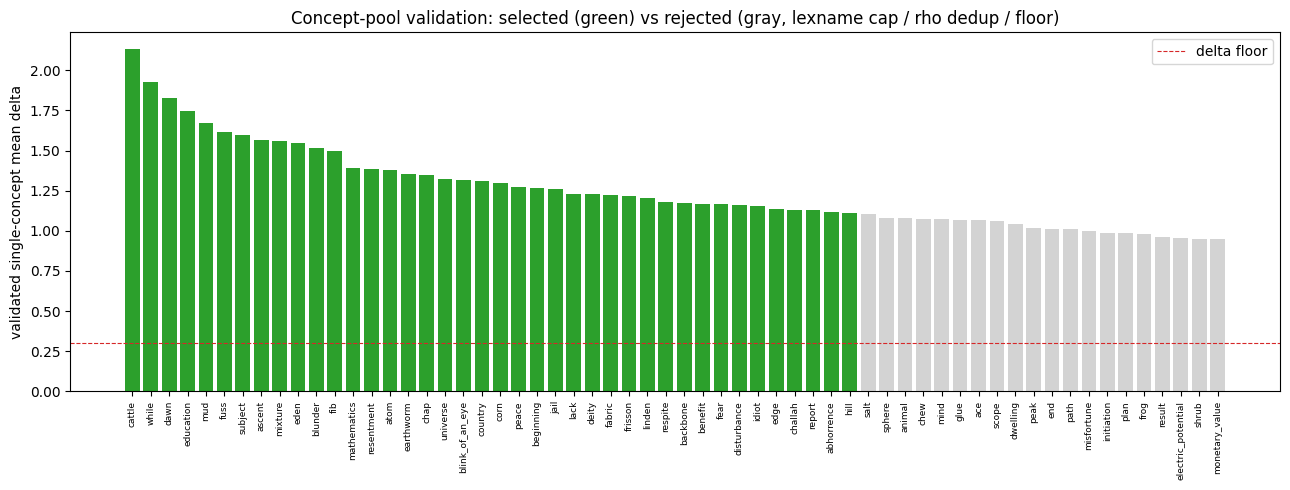

pool by lexname:
  noun.act               education, blunder
  noun.animal            cattle, earthworm
  noun.artifact          jail, fabric
  noun.attribute         backbone, benefit
  noun.cognition         mathematics
  noun.communication     subject, fib, report
  noun.event             fuss
  noun.feeling           resentment, peace, frisson, fear, abhorrence
  noun.food              challah
  noun.location          eden, country, beginning, edge
  noun.object            ascent, universe, hill
  noun.person            chap, deity, idiot
  noun.plant             corn, linden
  noun.state             lack, disturbance
  noun.substance         mud, mixture, atom
  noun.time              while, dawn, blink_of_an_eye, respite


In [7]:
fig, ax = plt.subplots(figsize=(13, 5))
top = cand.head(60)
bar_colors = ["tab:green" if n in pool else "lightgray" for n in top.index]
ax.bar(range(len(top)), top["delta"], color=bar_colors)
ax.axhline(DELTA_FLOOR, color="tab:red", ls="--", lw=0.8, label="delta floor")
ax.set_xticks(range(len(top)))
ax.set_xticklabels([n.split(".")[0] for n in top.index], rotation=90, fontsize=6.5)
ax.set_ylabel("validated single-concept mean delta")
ax.set_title(
    "Concept-pool validation: selected (green) vs rejected (gray, "
    "lexname cap / rho dedup / floor)"
)
ax.legend()
plt.tight_layout()
plt.savefig("resources/27_pool_deltas.png", dpi=150)
plt.show()

print("pool by lexname:")
for lex, group in cand.loc[pool].groupby("lexname"):
    heads = ", ".join(n.split(".")[0] for n in group.index)
    print(f"  {lex:22s} {heads}")

In [8]:
def answer(text: str) -> str:
    marker = "assistant<|end_header_id|>"
    return text.split(marker)[-1].strip() if marker in text else text


validation = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
shown = 0
for n in cand.index:
    if n in INCUMBENTS or n not in pool:
        continue
    for r in validation:
        if r["config"]["concept"] == n and "short story" in r["prompt"]:
            print(f"[{n}] delta={r['expression'][n]['delta']:+.2f}")
            print("   ", answer(r["text"])[:180], "\n")
            shown += 1
            break
    if shown == 5:
        break

[cattle.n.01] delta=+0.39
    Once upon time there were two brothers. They lived on an idillic farm surrounded rolling hills, fields and dense forest.

The 

[while.n.01] delta=+0.12
    Once upon a tiny, forgotten alley in a bustling metrópole, nestled in between towering skyscrappers stood an antique clock shop 

[dawn.n.01] delta=+0.47
    Once upon in Tokyo there was an alley known only by locals. It ran through one of Japan'Tokyo'S oldest wards called K 

[education.n.01] delta=+0.14
    Once, there existed in Japan an old man with an unquovaled passion. For as long he lived – over a century 

[mud.n.01] delta=+0.55
    Once in ancient Japan there was hidden away in mist-shaken mountains, in temples carved out from stone, lived an enka singer 

